# 10 · Word Embeddings: Word2Vec (skip-gram with negative sampling)

Neural networks need numbers, not words. A one-hot vector for each word treats "cat" and "dog" as exactly as unrelated as "cat" and "car". **Word embeddings** give every word a short dense vector so that *similar words get similar vectors*. This is the `Embedding` layer that notebook 07 used without explaining where good values come from.

**The distributional idea:** *a word is known by the company it keeps.* Words appearing in similar contexts (cat, dog, horse: "the ___ eats", "the ___ sleeps") should end up close together.

## Skip-gram
Slide a window over text. For each **center** word $c$ predict a **context** word $o$ within a few positions. Every word has two vectors: $w_c$ (as a center, rows of $W_{in}$) and $u_o$ (as a context, rows of $W_{out}$). Score a pair with a dot product, $w_c\cdot u_o$.

A full softmax over the whole vocabulary is expensive. **Negative sampling** turns it into cheap binary classification: the true pair $(c,o)$ should score high, and $K$ randomly drawn "noise" words $n_k$ should score low:
$$L=-\log\sigma(u_o\!\cdot\! w_c)\;-\;\sum_{k=1}^{K}\log\sigma(-u_{n_k}\!\cdot\! w_c)$$

**Gradients.** With $g_o=\sigma(u_o\cdot w_c)-1$ and $g_k=\sigma(u_{n_k}\cdot w_c)$:
$$\frac{\partial L}{\partial u_o}=g_o\,w_c,\qquad \frac{\partial L}{\partial u_{n_k}}=g_k\,w_c,\qquad \frac{\partial L}{\partial w_c}=g_o\,u_o+\sum_k g_k\,u_{n_k}$$

Noise words are drawn from the unigram distribution raised to the $3/4$ power, $P(w)\propto \text{count}(w)^{0.75}$, which gives rare words a bit more chance.

## The data
We use a **synthetic corpus with known structure** instead of downloading text. It has animals, fruits, vehicles, countries with their capitals, and **male/female word pairs** (king/queen, man/woman, ...) that share a role but differ in gender, plus function words. Because we know the true categories, we can *measure* what the embeddings learned instead of eyeballing a few neighbors.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [2]:
GROUPS = {
    "animal":  ["cat", "dog", "horse", "cow", "sheep", "pig", "duck", "bird"],
    "fruit":   ["apple", "banana", "grape", "orange", "pear", "mango"],
    "vehicle": ["car", "bus", "train", "truck", "bike", "plane", "boat"],
}
PAIRS = [("france", "paris"), ("italy", "rome"), ("spain", "madrid"), ("germany", "berlin"),
         ("japan", "tokyo"), ("egypt", "cairo"), ("russia", "moscow"), ("china", "beijing")]
GROUPS["country"] = [c for c, _ in PAIRS]
GROUPS["capital"] = [k for _, k in PAIRS]
CATEGORY = {w: g for g, ws in GROUPS.items() for w in ws}
PLACES = ["barn", "field", "garden", "house"]
GENDER = [("king", "queen"), ("man", "woman"), ("boy", "girl"), ("uncle", "aunt"),
          ("brother", "sister"), ("father", "mother"), ("prince", "princess"), ("actor", "actress")]
ROLES = ["rules the land", "walks to town", "plays outside", "visits us",
         "helps me", "cares for us", "lives in the castle", "acts on stage"]


def make_corpus(n_sentences, seed):
    rng = np.random.RandomState(seed)
    pick = lambda xs: xs[rng.randint(len(xs))]
    templates = [
        lambda: f"the {pick(GROUPS['animal'])} eats the {pick(GROUPS['fruit'])}",
        lambda: f"the {pick(GROUPS['animal'])} sleeps in the {pick(PLACES)}",
        lambda: f"a {pick(GROUPS['animal'])} runs fast",
        lambda: f"i eat a {pick(GROUPS['fruit'])}",
        lambda: f"the {pick(GROUPS['vehicle'])} travels to {pick(GROUPS['capital'])}",
        lambda: f"a {pick(GROUPS['vehicle'])} is fast",
        lambda: "the capital of {0} is {1}".format(*(p := pick(PAIRS))),
        lambda: "{1} is a city in {0}".format(*(p := pick(PAIRS))),
        lambda: "i travel from {0} to {1}".format(*(p := pick(PAIRS))),
        lambda: "the {0} {1}".format(*(lambda i, g: (GENDER[i][g], ROLES[i]))(rng.randint(len(GENDER)), rng.randint(2))),
        lambda: "the {0} said {1} was happy".format(*(lambda i, g: (GENDER[i][g], ("he", "she")[g]))(rng.randint(len(GENDER)), rng.randint(2))),
        lambda: "the {0} lost {1} hat".format(*(lambda i, g: (GENDER[i][g], ("his", "her")[g]))(rng.randint(len(GENDER)), rng.randint(2))),
    ]
    return [templates[rng.randint(len(templates))]().split() for _ in range(n_sentences)]


corpus = make_corpus(30000, seed=0)
vocab = sorted({w for s in corpus for w in s})
w2i = {w: i for i, w in enumerate(vocab)}
counts = np.bincount([w2i[w] for s in corpus for w in s], minlength=len(vocab))
V = len(vocab)
print(f"{len(corpus)} sentences, {counts.sum()} tokens, vocabulary of {V} words")
for s in corpus[:6]:
    print("  ", " ".join(s))

30000 sentences, 154421 tokens, vocabulary of 100 words
   a car is fast
   i eat a orange
   i eat a banana
   i eat a mango
   a sheep runs fast
   moscow is a city in russia


## Training pairs
For every sentence and every offset $1\ldots$`window`, emit (center, context) pairs in both directions. Pairs never cross sentence boundaries.

In [3]:
def build_pairs(sentences, window=2):
    centers, contexts = [], []
    for s in sentences:
        ids = np.array([w2i[w] for w in s])
        for d in range(1, window + 1):
            if len(ids) > d:
                centers += [ids[:-d], ids[d:]]
                contexts += [ids[d:], ids[:-d]]
    return np.concatenate(centers), np.concatenate(contexts)


centers, contexts = build_pairs(corpus)
print(f"{len(centers)} (center, context) training pairs")

noise_p = counts ** 0.75
noise_p = noise_p / noise_p.sum()        # unigram^0.75 negative-sampling distribution

437684 (center, context) training pairs


## The model
`forward_backward` computes the loss and writes dense gradient arrays for both embedding tables. Sparse updates are accumulated with `np.add.at`, which correctly sums contributions when the same word appears several times in a batch.

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def softplus(z):
    return np.logaddexp(0, z)


class SkipGramNS:
    def __init__(self, vocab_size, dim, seed=0):
        r = np.random.RandomState(seed)
        self.W_in = r.randn(vocab_size, dim) * 0.1       # center-word vectors (the embeddings we keep)
        self.W_out = r.randn(vocab_size, dim) * 0.1      # context-word vectors
        self.dW_in, self.dW_out = np.zeros_like(self.W_in), np.zeros_like(self.W_out)

    def forward_backward(self, c, o, neg):
        """c: (B,) centers, o: (B,) true contexts, neg: (B,K) noise words. Returns mean loss."""
        B = len(c)
        w, u_pos, u_neg = self.W_in[c], self.W_out[o], self.W_out[neg]          # (B,D), (B,D), (B,K,D)
        s_pos = (w * u_pos).sum(axis=1)                                        # (B,)
        s_neg = np.einsum("bd,bkd->bk", w, u_neg)                              # (B,K)
        loss = np.mean(softplus(-s_pos) + softplus(s_neg).sum(axis=1))

        g_pos = (sigmoid(s_pos) - 1) / B                                       # dL/ds for the true pair
        g_neg = sigmoid(s_neg) / B                                             # dL/ds for each noise pair
        dw = g_pos[:, None] * u_pos + np.einsum("bk,bkd->bd", g_neg, u_neg)
        self.dW_in[...] = 0
        np.add.at(self.dW_in, c, dw)
        self.dW_out[...] = 0
        np.add.at(self.dW_out, o, g_pos[:, None] * w)
        np.add.at(self.dW_out, neg, g_neg[:, :, None] * w[:, None, :])
        return loss

    def parameters(self):
        return [(self.W_in, self.dW_in), (self.W_out, self.dW_out)]


class Adam:
    def __init__(self, pairs, lr=0.01, b1=0.9, b2=0.999, eps=1e-8):
        self.pairs, self.lr, self.b1, self.b2, self.eps, self.t = pairs, lr, b1, b2, eps, 0
        self.m = [np.zeros_like(p) for p, _ in pairs]
        self.v = [np.zeros_like(p) for p, _ in pairs]

    def step(self):
        self.t += 1
        for i, (p, g) in enumerate(self.pairs):
            self.m[i] = self.b1 * self.m[i] + (1 - self.b1) * g
            self.v[i] = self.b2 * self.v[i] + (1 - self.b2) * g ** 2
            p -= self.lr * (self.m[i] / (1 - self.b1 ** self.t)) / (np.sqrt(self.v[i] / (1 - self.b2 ** self.t)) + self.eps)

## Verify the gradients
Finite-difference check on both embedding tables, with the noise words held fixed so the loss is a deterministic function of the weights.

In [5]:
def grad_check(loss_fn, pairs, samples_per_param=10, eps=1e-5, seed=0):
    """Worst relative error between analytic grads and central finite differences."""
    rng = np.random.RandomState(seed)
    worst = 0.0
    pairs = [(p, g.copy()) for p, g in pairs]          # snapshot: loss_fn may overwrite the live grad arrays
    for p, g in pairs:
        for _ in range(samples_per_param):
            idx = tuple(rng.randint(0, s) for s in p.shape)
            orig = p[idx]
            p[idx] = orig + eps; lp = loss_fn()
            p[idx] = orig - eps; lm = loss_fn()
            p[idx] = orig
            num = (lp - lm) / (2 * eps)
            worst = max(worst, abs(num - g[idx]) / (abs(num) + abs(g[idx]) + 1e-6))
    return worst


r = np.random.RandomState(0)
chk = SkipGramNS(V, 8, seed=1)
c_b, o_b = centers[:32], contexts[:32]
neg_b = r.choice(V, size=(32, 5), p=noise_p)
chk.forward_backward(c_b, o_b, neg_b)
err = grad_check(lambda: chk.forward_backward(c_b, o_b, neg_b), chk.parameters())
print(f"worst relative error {err:.2e}")
assert err < 1e-5, "skip-gram gradients disagree with finite differences"

worst relative error 4.48e-08


## Train

In [6]:
DIM, K, BATCH, EPOCHS = 24, 5, 1024, 8

model = SkipGramNS(V, DIM, seed=1)
opt = Adam(model.parameters(), lr=0.01)
rng = np.random.RandomState(0)

losses = []
for epoch in range(EPOCHS):
    perm = rng.permutation(len(centers))
    total = 0.0
    for i in range(0, len(perm), BATCH):
        b = perm[i:i + BATCH]
        neg = rng.choice(V, size=(len(b), K), p=noise_p)
        total += model.forward_backward(centers[b], contexts[b], neg) * len(b)
        opt.step()
    losses.append(total / len(perm))
    print(f"epoch {epoch + 1}/{EPOCHS}  loss {losses[-1]:.4f}")

epoch 1/8  loss 1.6887


epoch 2/8  loss 1.3296


epoch 3/8  loss 1.3249


epoch 4/8  loss 1.3239


epoch 5/8  loss 1.3229


epoch 6/8  loss 1.3218


epoch 7/8  loss 1.3226


epoch 8/8  loss 1.3206


## Did it learn meaningful structure?
Two quantitative tests (we know the ground truth):

1. **Neighbor purity.** For every word that belongs to a category, take its 3 nearest neighbors by cosine similarity; what fraction belong to the *same* category?
2. **Analogies.** The classic $\text{king}:\text{queen}::\text{man}:\,?$ test. Solve with vector arithmetic: the answer is the word closest (cosine) to $w_{\text{queen}}-w_{\text{king}}+w_{\text{man}}$, excluding the three given words. Averaged over all 56 ordered pairs of male/female pairs.

Why this works here: every male word shares "he/his" contexts and every female word "she/her" ones, while each *pair* shares its own role context (king/queen "rules the land"). So $w_{\text{female}}-w_{\text{male}}$ is roughly the same offset for every pair.

In [7]:
def normalize(E):
    return E / np.linalg.norm(E, axis=1, keepdims=True)


def neighbors(E, word, k=3):
    En = normalize(E)
    sims = En @ En[w2i[word]]
    sims[w2i[word]] = -np.inf
    return [vocab[i] for i in np.argsort(-sims)[:k]]


def purity(E, k=3):
    scores = [np.mean([CATEGORY[n] == CATEGORY[w] for n in neighbors(E, w, k) if n in CATEGORY] or [0])
              for w in CATEGORY]
    return float(np.mean(scores))


def analogy_accuracy(E):
    En = normalize(E)
    hits = total = 0
    for a, b in GENDER:
        for c, d in GENDER:
            if a == c:
                continue
            q = En[w2i[b]] - En[w2i[a]] + En[w2i[c]]
            sims = En @ q
            sims[[w2i[a], w2i[b], w2i[c]]] = -np.inf
            hits += vocab[int(np.argmax(sims))] == d
            total += 1
    return hits / total


E_sg = model.W_in
for w in ["cat", "apple", "bus", "france", "king"]:
    print(f"{w:<8} -> {neighbors(E_sg, w, 4)}")
print(f"\nneighbor purity:   {purity(E_sg):.0%}")
print(f"gender analogy accuracy:  {analogy_accuracy(E_sg):.0%}   (chance would be about {1 / (V - 3):.0%})")

cat      -> ['bird', 'pig', 'sheep', 'horse']
apple    -> ['banana', 'grape', 'mango', 'orange']
bus      -> ['train', 'bike', 'boat', 'car']
france   -> ['japan', 'italy', 'china', 'egypt']
king     -> ['land', 'actor', 'boy', 'father']

neighbor purity:   88%
gender analogy accuracy:  100%   (chance would be about 1%)


## A classical baseline: PPMI + SVD
Before neural embeddings, the standard recipe was: count how often words co-occur, convert to **pointwise mutual information**
$$\text{PMI}(w,c)=\log\frac{P(w,c)}{P(w)P(c)},\qquad \text{PPMI}=\max(0,\text{PMI})$$
and factorize the matrix with an SVD. Levy & Goldberg (2014) showed skip-gram with negative sampling is *implicitly factorizing a shifted PMI matrix*, so the two should behave similarly. Same counts, same dimension — no neural network at all.

In [8]:
C = np.zeros((V, V))
np.add.at(C, (centers, contexts), 1)
total = C.sum()
pmi = np.log((C * total + 1e-12) / (np.outer(C.sum(axis=1), C.sum(axis=0)) + 1e-12))
ppmi = np.maximum(pmi, 0)
U, S, _ = np.linalg.svd(ppmi)
E_svd = U[:, :DIM] * np.sqrt(S[:DIM])

print(f"{'':<22}{'neighbor purity':<18}{'analogy accuracy'}")
print(f"{'skip-gram (SGNS)':<22}{purity(E_sg):<18.0%}{analogy_accuracy(E_sg):.0%}")
print(f"{'PPMI + SVD':<22}{purity(E_svd):<18.0%}{analogy_accuracy(E_svd):.0%}")
E_rand = np.random.RandomState(3).randn(V, DIM)
print(f"{'random vectors':<22}{purity(E_rand):<18.0%}{analogy_accuracy(E_rand):.0%}")

assert purity(E_sg) > 0.8, "skip-gram neighbors should mostly share a category"
assert analogy_accuracy(E_sg) > 0.5, "vector arithmetic should solve most gender analogies"
assert purity(E_sg) > purity(E_rand) + 0.4, "embeddings should beat random vectors"

                      neighbor purity   analogy accuracy
skip-gram (SGNS)      88%               100%
PPMI + SVD            100%              100%
random vectors        21%               4%


## Visualizing the embedding space
Project the 24-dimensional vectors to 2-D with PCA (SVD of the centered matrix). Left: all category words, colored by group. Right: the male/female pairs, drawn along the **average male→female direction** (x-axis) so that a consistent offset shows up as parallel, equal-length arrows. (In a generic 2-D PCA the gender direction need not be a top component, so we choose the axis ourselves.) The title reports how aligned each pair's own offset is with that average.

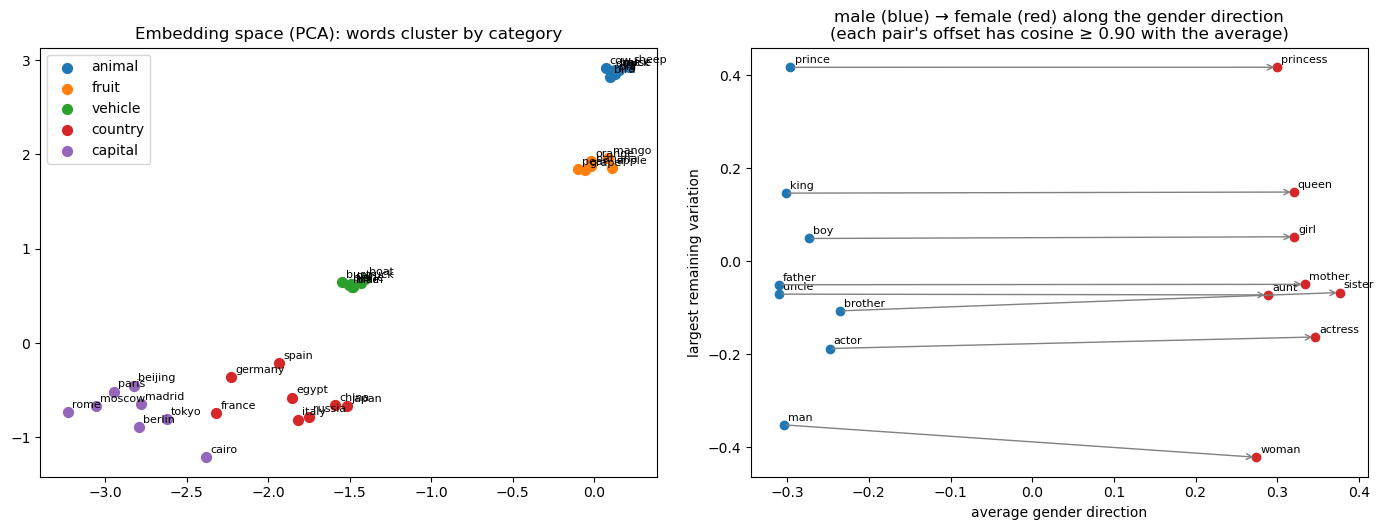

In [9]:
def pca2(E):
    X = E - E.mean(axis=0)
    _, _, Vt = np.linalg.svd(X, full_matrices=False)
    return X @ Vt[:2].T


P = pca2(E_sg)
colors = {"animal": "C0", "fruit": "C1", "vehicle": "C2", "country": "C3", "capital": "C4"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for g, ws in GROUPS.items():
    idx = [w2i[w] for w in ws]
    axes[0].scatter(P[idx, 0], P[idx, 1], c=colors[g], label=g, s=50)
    for w, i in zip(ws, idx):
        axes[0].annotate(w, P[i], fontsize=8, xytext=(3, 3), textcoords="offset points")
axes[0].set(title="Embedding space (PCA): words cluster by category"); axes[0].legend()

# Right panel: x-axis = the AVERAGE male->female direction, y-axis = the largest remaining variation among these words.
# (A generic 2-D PCA need not contain the gender direction, so arrows would look scattered even when the offset is consistent.)
En = normalize(E_sg)
offsets = np.array([En[w2i[f]] - En[w2i[m]] for m, f in GENDER])
d = offsets.mean(axis=0); d /= np.linalg.norm(d)
offset_cos = offsets @ d / np.linalg.norm(offsets, axis=1)
words = [w for pair in GENDER for w in pair]
R = En[[w2i[w] for w in words]]
R_perp = R - np.outer(R @ d, d)
y_dir = np.linalg.svd(R_perp - R_perp.mean(axis=0), full_matrices=False)[2][0]
xy = lambda w: np.array([En[w2i[w]] @ d, En[w2i[w]] @ y_dir])
for (c, k) in GENDER:
    a, b = xy(c), xy(k)
    axes[1].annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color="gray"))
    axes[1].scatter(*a, c="C0"); axes[1].scatter(*b, c="C3")
    axes[1].annotate(c, a, fontsize=8, xytext=(3, 3), textcoords="offset points")
    axes[1].annotate(k, b, fontsize=8, xytext=(3, 3), textcoords="offset points")
axes[1].set(title=f"male (blue) → female (red) along the gender direction\n(each pair's offset has cosine ≥ {offset_cos.min():.2f} with the average)",
            xlabel="average gender direction", ylabel="largest remaining variation")
plt.tight_layout(); plt.show()

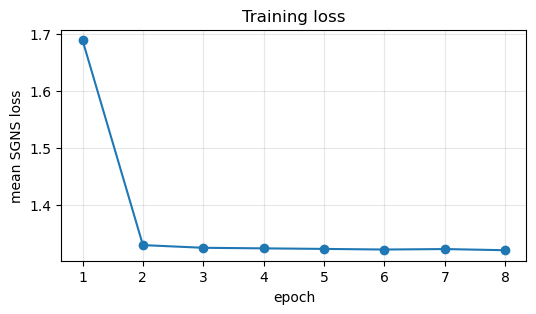

In [10]:
plt.figure(figsize=(6, 3))
plt.plot(range(1, EPOCHS + 1), losses, marker="o")
plt.xlabel("epoch"); plt.ylabel("mean SGNS loss"); plt.title("Training loss"); plt.grid(alpha=0.3)
plt.show()

## Takeaways
- **Embeddings come from prediction.** No labels about categories were ever given; words end up clustered purely because they share contexts.
- **Negative sampling** replaces an expensive $|V|$-way softmax with $K+1$ cheap binary decisions.
- **Two tables, one kept.** $W_{in}$ (center) and $W_{out}$ (context) are trained jointly; the embeddings are usually $W_{in}$ (some use their sum).
- **Skip-gram ≈ PMI factorization.** The count-based PPMI+SVD matches (here even beats) skip-gram with no training loop. That is expected on a tiny, clean corpus; the neural version earns its keep on huge vocabularies and corpora where the full count matrix no longer fits.
- **Caveats of this toy setup:** the corpus is template-generated and tiny, so purity/analogy numbers are much cleaner than on real text (real analogies are noisier). Frequent-word subsampling is skipped because the vocabulary is small.

Things to try: change `DIM`, `K` or `window`; remove the he/she templates and watch the gender analogy accuracy collapse: the offset direction has nothing left to be built from.

**Next**: residual networks (`11`) and an autograd engine (`12`).